## **Important Information:**
1.   The pretraied model is loaded in the variable `model`.
2.   All clean images and labels are loaded as tensors `X` and `y_true` respectively such that `y_true[i]` is the actual label of `X[i]`.
3.   To predict all labels call `model(X)`.
4.   Please properly follow the instructions corresponding to each of the following cells.

## **Specify the data path**
In the following cell provide appropriate path to the "p2_data.zip" file.

In [1]:
# EDIT THE PATH IF NEEDED
import os, glob, zipfile
zip_path = "p2_data.zip" if os.path.exists("p2_data.zip") else "../p2_data.zip" # path to the "p2_data.zip" file.

# Fresh clone of the repo: the data is already extracted in p2_data/, so rebuild the zip the next cell expects
# (same contents as the organisers' zip: readme, model, clean images, empty adv_images/).
if not os.path.exists(zip_path) and os.path.isdir("p2_data/clean_images"):
    zip_path = "p2_data.zip"
    with zipfile.ZipFile(zip_path, "w") as z:
        z.writestr("p2_data/adv_images/", "")
        for f in ["p2_data/readme.txt", "p2_data/cnn_model.pt"] + sorted(glob.glob("p2_data/clean_images/*.png")):
            z.write(f)
    print(f"Rebuilt {zip_path} from p2_data/")

## **Load data file**
**Do not edit the following cell.**

In [2]:
# DO NOT EDIT THIS CELL

import zipfile

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall()

with open("./p2_data/readme.txt", "r") as f:
    print(f.read())

readme.txt:
-----------

Clean images are available in the folder "/p2_data/clean_images/"

There are 1000 clean images (10 classes * 100 images per class)

Image file path format is "/p2_data/clean_images/<class_name>_<index>.png"
     <class_name>: Name of the true class of the image
                   Can be among {airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck}
     <index>     : Index of the image ranging from 0 to 99

There is an empty folder "/p2_data/adv_images/". You can use it for saving your adversarial images.

The pretrained model is "/p2_data/cnn_model.pt"


## **Prepare the model and data**
1. **Do not edit the following cell.**
2. The variable `class_names` contains name of the output labels.
3. The variables `mean` and `std` are used to normalize the input images using mean and standard deviation.



Total images: 1000  |  Correctly Classified: 1000
Showing some sample images ...


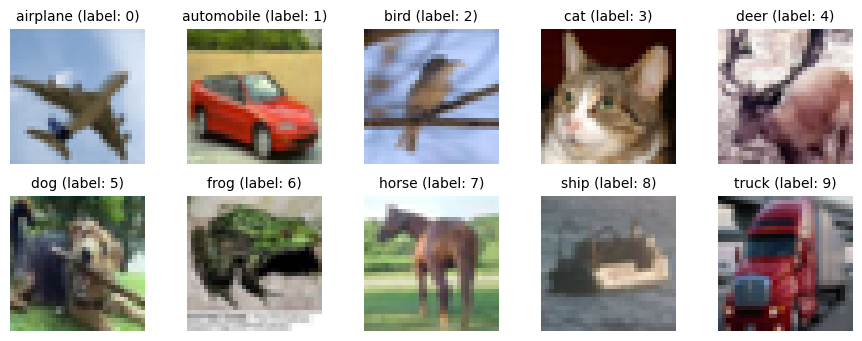

In [3]:
# DO NOT EDIT THIS CELL

import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

mean = (0.4914, 0.4822, 0.4465) # image mean
std  = (0.2470, 0.2435, 0.2616) # image standard deviation
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
img_per_class = 100

# prepare input images
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)]) # specify transformations: covert to tensor and normalize
paths = [f"./p2_data/clean_images/{name}_{i}.png" for name in class_names for i in range(img_per_class)]
labels = [class_names.index(name) for name in class_names for _ in range(img_per_class)]
X = torch.stack([transform(Image.open(p).convert("RGB")) for p in paths], dim = 0).to(device) # convert to tensor and normalize
y_true = torch.tensor(labels).to(device) # convert to tensor

# load cnn model
model = torch.jit.load("./p2_data/cnn_model.pt", map_location = device)

# sanity check
y_pred = model(X)
matches = (y_true == y_pred)
print(f"Total images: {len(y_true)}  |  Correctly Classified: {sum(matches).item()}")

# show some images
print("Showing some sample images ...")
mean_t = torch.tensor(mean).view(3, 1, 1)
std_t  = torch.tensor(std).view(3, 1, 1)
fig, axes = plt.subplots(2, 5, figsize=(9, 3.5))
for i, idx in enumerate([59, 119, 283, 360, 427, 527, 682, 783, 806, 991]):
    img = (X[idx].cpu() * std_t + mean_t).clamp(0, 1)
    img = img.permute(1, 2, 0).numpy()
    ax = axes[i // 5, i % 5]
    ax.imshow(img)
    ax.set_title(f"{class_names[idx // img_per_class]} (label: {labels[idx]})", fontsize = 10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## **Helper 1: pixel space ↔ normalized space**
All attack work happens in **[0, 1] pixel space**; images are normalized only inside the oracle.
`quantize` snaps images to the 8-bit grid a PNG can store, so every image we test is exactly the image we save
(rounding, not truncating — truncation alone shifts ~14% of pixel values by 1/255).

In [4]:
import os, json, glob, math, time, tempfile
import numpy as np
from skimage.metrics import structural_similarity

MEAN_T = torch.tensor(mean, device=device).view(1, 3, 1, 1)
STD_T  = torch.tensor(std,  device=device).view(1, 3, 1, 1)

def to_pixel(x_norm):
    """Normalized images -> [0, 1] pixel space."""
    return (x_norm.to(device) * STD_T + MEAN_T).clamp(0, 1)

def to_normalized(x_pix):
    """[0, 1] pixel space -> normalized images (what the model expects)."""
    return (x_pix.to(device) - MEAN_T) / STD_T

def quantize(x_pix):
    """Clip to [0, 1] and round to the nearest k/255."""
    return torch.round(x_pix.clamp(0, 1) * 255) / 255

X_pix = quantize(to_pixel(X))                                           # clean images, exactly the PNG pixels / 255
file_stems = [os.path.splitext(os.path.basename(p))[0] for p in paths]  # e.g. "cat_5"

## **Helper 2: `QueryModel` — the hard-label oracle**
Takes a batch of [0, 1] images, normalizes them, calls `model()` and returns **predicted labels only**.
TF32 is switched off so labels are computed in full FP32: with TF32 on (the PyTorch default on recent NVIDIA GPUs),
an image near the decision boundary can get a different label depending on the batch size it's queried in.
Each image in a batch is one query. Passing `idx` (the dataset index of each row, or one int for the whole batch)
charges those queries to that image in `oracle.queries`; `oracle.total` counts every query, charged or not.

In [5]:
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

class QueryModel:
    def __init__(self, model, n_images, batch_size=500):
        self.model = model
        self.batch_size = batch_size
        self.queries = torch.zeros(n_images, dtype=torch.long)  # attack queries charged per image
        self.total = 0                                           # all queries, including uncharged checks

    @torch.no_grad()
    def predict(self, x_pix, idx=None):
        """Predicted labels for a batch (B, 3, 32, 32) in [0, 1]."""
        x_pix = x_pix.to(device)
        preds = torch.cat([self.model(to_normalized(chunk)) for chunk in x_pix.split(self.batch_size)])
        self.total += len(x_pix)
        if idx is not None:
            idx = torch.as_tensor(idx).view(-1).cpu()
            if idx.numel() == 1:
                idx = idx.expand(len(x_pix))
            self.queries.index_add_(0, idx, torch.ones(len(idx), dtype=torch.long))
        return preds

    def is_adversarial(self, x_pix, true_labels, idx=None):
        """True where the predicted label differs from the true label."""
        return self.predict(x_pix, idx) != true_labels.to(device)

    def reset(self):
        self.queries.zero_()
        self.total = 0

oracle = QueryModel(model, len(X))

## **Helper 3: perturbation metrics**
Compares clean and adversarial images in [0, 1] space: L2, L∞, SSIM and PSNR per image, plus averages.
PSNR is infinite for an unchanged image, so the average PSNR is taken over changed images only.

In [6]:
def compute_metrics(clean, adv):
    """clean, adv: (B, 3, H, W) in [0, 1]. Returns (per-image dict of arrays, dict of averages)."""
    c, a = clean.detach().double().cpu(), adv.detach().double().cpu()
    diff = (a - c).flatten(1)
    per = {
        "L2":   diff.norm(dim=1).numpy(),
        "Linf": diff.abs().max(dim=1).values.numpy(),
        "SSIM": np.array([structural_similarity(ci, ai, data_range=1.0, channel_axis=0)
                          for ci, ai in zip(c.numpy(), a.numpy())]),
        "PSNR": (10 * torch.log10(1.0 / diff.pow(2).mean(1))).numpy(),
    }
    avg = {k: float(v.mean()) for k, v in per.items() if k != "PSNR"}
    finite = per["PSNR"][np.isfinite(per["PSNR"])]
    avg["PSNR"] = float(finite.mean()) if len(finite) else float("inf")
    return per, avg

## **Helper 4: save, verify and log results**
`save_and_verify` clips, rounds to uint8 and writes `<name>_adv.png` (e.g. `cat_5.png` → `cat_5_adv.png`),
then reloads the PNGs from disk and checks they still fool the model (this check isn't charged to any image).
`save_results` writes an attack's summary and per-image numbers to `results/<name>.json`;
`compare_results` prints every saved attack side by side.

In [7]:
def save_and_verify(adv_pix, indices, out_dir="p2_data/adv_images"):
    """Returns (reloaded images in [0, 1], bool tensor: still misclassified)."""
    os.makedirs(out_dir, exist_ok=True)
    indices = list(indices)
    arr = torch.round(adv_pix.detach().clamp(0, 1) * 255).to(torch.uint8).permute(0, 2, 3, 1).cpu().numpy()
    saved = []
    for img, i in zip(arr, indices):
        path = os.path.join(out_dir, f"{file_stems[i]}_adv.png")
        Image.fromarray(img).save(path)
        saved.append(path)
    reloaded = torch.stack([transforms.ToTensor()(Image.open(p).convert("RGB")) for p in saved]).to(device)
    fooled = oracle.is_adversarial(reloaded, y_true[indices]).cpu()
    print(f"Saved {len(saved)} images to {out_dir} | still misclassified after reload: {fooled.sum().item()}/{len(saved)}")
    return reloaded, fooled

def save_results(name, description, indices, per, avg, queries, fooled, folder="results"):
    os.makedirs(folder, exist_ok=True)
    summary = {"attack": name, "description": description, "n_images": len(indices),
               "success_rate": fooled.float().mean().item(),
               **{f"avg_{k}": v for k, v in avg.items()},
               "avg_queries": queries.float().mean().item()}
    rows = [{"image": file_stems[i], "queries": int(queries[j]), "fooled": bool(fooled[j]),
             **{k: float(per[k][j]) for k in per}} for j, i in enumerate(indices)]
    with open(f"{folder}/{name}.json", "w") as f:
        json.dump({"summary": summary, "indices": list(indices), "per_image": rows}, f, indent=2)
    return summary

def compare_results(folder="results", names=None):
    """Print saved summaries side by side: every <folder>/*.json, or just `names` in that order."""
    paths = [f"{folder}/{n}.json" for n in names] if names else sorted(glob.glob(f"{folder}/*.json"))
    print(f"{'attack':<16}{'n':>4}{'success':>9}{'L2':>8}{'Linf':>8}{'SSIM':>8}{'PSNR':>8}{'queries':>9}")
    for path in paths:
        s = json.load(open(path))["summary"]
        print(f"{s['attack']:<16}{s['n_images']:>4}{s['success_rate']:>9.0%}{s['avg_L2']:>8.3f}{s['avg_Linf']:>8.3f}"
              f"{s['avg_SSIM']:>8.3f}{s['avg_PSNR']:>8.2f}{s['avg_queries']:>9.1f}")

## **Helper 5: clean images the model already gets wrong**
One uncharged query per image. These images need no attack: the clean image is kept as-is with zero queries.

In [8]:
clean_pred = oracle.predict(X_pix)
already_wrong = (clean_pred != y_true).cpu()
wrong_idx = already_wrong.nonzero().flatten().tolist()
print(f"Model misclassifies {len(wrong_idx)}/{len(X)} clean images")
for i in wrong_idx:
    print(f"  {file_stems[i]}: predicted {class_names[clean_pred[i]]}")

Model misclassifies 0/1000 clean images


## **Helper self-test on the first 20 images**
Checks the conversion round trip, per-image query counting, the metrics, and the PNG save/reload path
(written to a temporary folder so `p2_data/adv_images` stays clean). Counters are reset afterwards.

In [9]:
torch.manual_seed(0)
test_idx = list(range(20))
x20, y20 = X_pix[test_idx], y_true[test_idx]

print("max |to_normalized(X_pix) - X|:", (to_normalized(x20) - X[test_idx]).abs().max().item())

fooled = oracle.is_adversarial(x20, y20, idx=test_idx)
print("clean images flagged adversarial:", fooled.sum().item(), "| queries charged:", oracle.queries[test_idx].tolist())

_, avg = compute_metrics(x20, x20)
print("clean vs clean:     ", {k: round(v, 4) for k, v in avg.items()})
noisy = quantize(x20 + (torch.rand_like(x20) * 2 - 1) * 8 / 255)
_, avg = compute_metrics(x20, noisy)
print("clean vs +-8/255 noise:", {k: round(v, 4) for k, v in avg.items()})

with tempfile.TemporaryDirectory() as tmp:
    reloaded, _ = save_and_verify(x20, test_idx, out_dir=tmp)
    exact = torch.equal(torch.round(reloaded * 255), torch.round(x20 * 255))   # compare 8-bit values (GPU/CPU /255 can differ by 1 ulp)
    print("PNG round trip exact:", exact, "| files:", sorted(os.listdir(tmp))[:3], "...")
oracle.reset()

max |to_normalized(X_pix) - X|: 4.76837158203125e-07
clean images flagged adversarial: 0 | queries charged: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
clean vs clean:      {'L2': 0.0, 'Linf': 0.0, 'SSIM': 1.0, 'PSNR': inf}
clean vs +-8/255 noise: {'L2': 1.0038, 'Linf': 0.0314, 'SSIM': 0.9448, 'PSNR': 34.8422}


Saved 20 images to C:\Users\244764~1\AppData\Local\Temp\tmp_kq8z11f | still misclassified after reload: 0/20
PNG round trip exact: True | files: ['airplane_0_adv.png', 'airplane_10_adv.png', 'airplane_11_adv.png'] ...


## **Baseline attack: random start + binary search**
For each image the model gets right:
1. **Starting point** — up to 10 uniform-noise images until one is misclassified. If none is, fall back to the
   nearest clean image (L2) that the model labels differently from the true class (known from Helper 5, so no extra queries).
2. **Binary search** (12 steps) on the line from the clean image to the start, keeping the closest point that is still
   misclassified. Every tested point is quantized, so the result stays adversarial once saved as a PNG.

Images the model already misclassifies are kept as-is with zero queries.
Run on 20 images, 2 per class (images `<class>_0` and `<class>_1`), so every class is represented; later attacks reuse `baseline_idx`.
Results are written to `results/baseline.json`, images to `results/baseline_images/`.

In [10]:
def find_start(x_clean, y, i, gen, max_noise_tries=10):
    for _ in range(max_noise_tries):
        cand = quantize(torch.rand(1, 3, 32, 32, generator=gen).to(device))
        if oracle.is_adversarial(cand, y, idx=i):
            return cand, "noise"
    others = (clean_pred != y.item()).nonzero().flatten()
    nearest = others[(X_pix[others] - x_clean).flatten(1).norm(dim=1).argmin()]
    return X_pix[nearest].unsqueeze(0), f"clean {file_stems[nearest]}"

def binary_search(x_clean, x_start, y, i, steps=12):
    lo, hi = 0.0, 1.0   # lo: clean side (correct), hi: adversarial side
    for _ in range(steps):
        mid = (lo + hi) / 2
        if oracle.is_adversarial(quantize(x_clean + mid * (x_start - x_clean)), y, idx=i):
            hi = mid
        else:
            lo = mid
    return quantize(x_clean + hi * (x_start - x_clean))

def run_baseline(indices, steps=12, seed=0):
    gen = torch.Generator().manual_seed(seed)
    advs, sources = [], []
    for i in indices:
        x, y = X_pix[i:i + 1], y_true[i:i + 1]
        if already_wrong[i]:
            advs.append(x); sources.append("already wrong")
            continue
        start, source = find_start(x, y, i, gen)
        advs.append(binary_search(x, start, y, i, steps)); sources.append(source)
    return torch.cat(advs), sources

oracle.reset()
baseline_idx = [c * img_per_class + k for c in range(10) for k in range(2)]
adv_baseline, sources = run_baseline(baseline_idx)

reloaded, fooled = save_and_verify(adv_baseline, baseline_idx, out_dir="results/baseline_images")
per, avg = compute_metrics(X_pix[baseline_idx], reloaded)
baseline_queries = oracle.queries[baseline_idx].clone()
adv_pred = oracle.predict(reloaded)

print(f"\n{'image':<14}{'start':<22}{'pred':<12}{'queries':>8}{'L2':>8}{'Linf':>7}{'SSIM':>7}{'PSNR':>7}")
for j, i in enumerate(baseline_idx):
    print(f"{file_stems[i]:<14}{sources[j]:<22}{class_names[adv_pred[j]]:<12}{baseline_queries[j].item():>8}"
          f"{per['L2'][j]:>8.3f}{per['Linf'][j]:>7.3f}{per['SSIM'][j]:>7.3f}{per['PSNR'][j]:>7.2f}")

summary = save_results("baseline", "noise / nearest-clean start + 12-step binary search",
                       baseline_idx, per, avg, baseline_queries, fooled)
print("\nBaseline summary:", json.dumps(summary, indent=2))
print()
compare_results()

Saved 20 images to results/baseline_images | still misclassified after reload: 20/20

image         start                 pred         queries      L2   Linf   SSIM   PSNR
airplane_0    noise                 ship              13   1.209  0.063  0.972  33.23
airplane_1    noise                 bird              13   2.118  0.071  0.849  28.35
automobile_0  noise                 frog              13   1.971  0.078  0.967  28.98
automobile_1  noise                 frog              13   3.397  0.153  0.882  24.25
bird_0        clean deer_64         deer              22   0.494  0.039  0.996  40.99
bird_1        clean airplane_54     airplane          22   0.636  0.067  0.984  38.81
cat_0         noise                 frog              13   3.527  0.141  0.875  23.93
cat_1         noise                 bird              13   4.627  0.212  0.727  21.57
deer_0        noise                 bird              13   6.589  0.306  0.656  18.50
deer_1        noise                 frog              

## **Shared attack utilities**
Used by HSJA, SurFree and CGBA so all three are measured the same way:
- `budgeted_phi` — the label-only adversarial test for one image; raises `OutOfBudget` instead of going over the query limit.
- `finalize_8bit` — attacks work in continuous space, and rounding to 8 bits can push a boundary point back into the true class
  (or erase a tiny perturbation entirely — some images have adversarial points at L2 ≈ 0.001, below a single 1/255 pixel step).
  It scales the best point outward along the ray clean → best (×1.2 per step) until the **rounded** image is adversarial,
  refines with a 4-step binary search, then pushes out by `margin` (default 1%) if that still fools the model.
  If the scaled point would be farther than the start point, the start point is kept. Attacks reserve queries for this.
  The margin keeps saved images off the exact boundary, so they still fool the model with TF32 or a different batch size.
- `note` — records (queries used, L2 of the best point) whenever an attack improves, for the L2-vs-queries curves.
- `run_attack` — runs an attack on a list of images from their start points. `budget` is the **total** queries per image,
  **including** the baseline queries used to find the start.

In [11]:
class OutOfBudget(Exception):
    pass

def budgeted_phi(y, i, limit):
    def phi(x):
        if oracle.queries[i].item() + len(x) > limit:
            raise OutOfBudget
        return oracle.is_adversarial(x, y.expand(len(x)), idx=i)
    return phi

def note(trace, i, x_adv, x_clean):
    if trace is not None:
        trace.append((oracle.queries[i].item(), (x_adv - x_clean).norm().item()))
        if hasattr(trace, "images"):   # a trace that also keeps the images (used to export animation frames)
            trace.images.append(x_adv.detach().clone())

def finalize_8bit(x_clean, best, x_start, y, i, budget, margin=0.01, trace=None):
    phi = lambda x: oracle.is_adversarial(x, y, idx=i)[0]
    ray = lambda s: quantize(x_clean + s * (best - x_clean))
    max_s = (x_start - x_clean).norm().item() / (best - x_clean).norm().item()   # beyond this x_start is closer
    lo, hi, final = 1 / 1.2, 1.0, None
    while not phi(ray(hi)):
        lo, hi = hi, hi * 1.2
        if hi >= max_s or budget - oracle.queries[i].item() < 6:
            final = x_start
            break
    if final is None:
        for _ in range(4):
            mid = (lo + hi) / 2
            if phi(ray(mid)):
                hi = mid
            else:
                lo = mid
        final = ray(hi * (1 + margin))
        if not phi(final):
            final = ray(hi)
    note(trace, i, final, x_clean)
    return final

def run_attack(attack, indices, x_starts, start_queries, budget, seed=0, traces=None, **kwargs):
    torch.manual_seed(seed)
    oracle.reset()
    oracle.queries[indices] = start_queries   # the start point's queries count toward the budget
    advs = []
    for j, i in enumerate(indices):
        x, y = X_pix[i:i + 1], y_true[i:i + 1]
        if already_wrong[i]:
            advs.append(x)
            continue
        trace = [] if traces is not None else None
        note(trace, i, x_starts[j:j + 1], x)
        advs.append(attack(x, x_starts[j:j + 1], y, i, budget, trace=trace, **kwargs))
        if traces is not None:
            traces[i] = trace
    return torch.cat(advs)

budgets = [1000, 2000, 5000]

## **HopSkipJumpAttack (Chen et al. 2020) — untargeted, L2**
A direct implementation of the reference algorithm. Its only access to the model is `oracle.is_adversarial`,
so it sees labels only and every query is charged to the image being attacked.

Starting from the baseline's binary-searched point, each iteration:
1. **Boundary search** — binary search between the clean image and the current adversarial point, down to tolerance θ = γ / d^1.5.
2. **Gradient-direction estimate** — `100·√t` random unit directions around the boundary point (δ = 0.1 on the first iteration, then √d·θ·dist).
   Each is labelled ±1 (adversarial or not); the mean of the label-weighted directions, with the mean label subtracted, estimates the boundary normal.
3. **Geometric step** — step size dist/√t along that direction, halved until the point is adversarial again, then back to 1.

The result goes through `finalize_8bit` (40 queries reserved). `max_iters` caps the iterations.

In [12]:
def hsja(x_clean, x_start, y, i, budget, max_iters=1000, init_evals=100, max_evals=10000, gamma=1.0,
         margin=0.01, reserve=40, trace=None, directions=None):
    """x_clean, x_start: (1, 3, H, W) in [0, 1]; x_start must be adversarial after quantization.
    directions(n, x_clean) -> (n, 3, H, W) raw sampling directions for the gradient estimate (default: Gaussian).
    Returns a quantized adversarial image; stops when max_iters or the query budget is reached."""
    d = x_clean.numel()
    theta = gamma / (d * math.sqrt(d))
    left = lambda: budget - reserve - oracle.queries[i].item()
    phi = lambda x: oracle.is_adversarial(x, y.expand(len(x)), idx=i)

    def boundary_search(x_adv):
        lo, hi = 0.0, 1.0   # fraction of the way from clean to x_adv; hi stays adversarial
        while hi - lo > theta and left() > 0:
            mid = (lo + hi) / 2
            if phi(x_clean + mid * (x_adv - x_clean))[0]:
                hi = mid
            else:
                lo = mid
        return x_clean + hi * (x_adv - x_clean)

    x = boundary_search(x_start)
    dist = (x - x_clean).norm().item()
    best, best_dist = x, dist
    note(trace, i, best, x_clean)
    for t in range(1, max_iters + 1):
        # 1. estimate the gradient direction of the decision boundary at x
        delta = 0.1 if t == 1 else math.sqrt(d) * theta * dist
        n = min(int(init_evals * math.sqrt(t)), max_evals, left() - 30)   # keep queries for step + boundary search
        if n < 10:
            break
        u = directions(n, x_clean) if directions else torch.randn(n, *x.shape[1:], device=device)
        u = u / u.flatten(1).norm(dim=1).view(-1, 1, 1, 1)
        perturbed = (x + delta * u).clamp(0, 1)
        u = (perturbed - x) / delta
        f = phi(perturbed).float() * 2 - 1
        if f.mean() == 1:
            g = u.mean(0)
        elif f.mean() == -1:
            g = -u.mean(0)
        else:
            g = ((f - f.mean()).view(-1, 1, 1, 1) * u).mean(0)
        g = g / g.norm()

        # 2. geometric step-size search: halve until adversarial again
        eps, stepped = dist / math.sqrt(t), False
        while left() > 0:
            cand = (x + eps * g).clamp(0, 1)
            if phi(cand)[0]:
                stepped = True
                break
            eps /= 2
        if not stepped:
            break

        # 3. project back onto the boundary
        x = boundary_search(cand)
        dist = (x - x_clean).norm().item()
        if dist < best_dist:
            best, best_dist = x, dist
            note(trace, i, best, x_clean)

    return finalize_8bit(x_clean, best, x_start, y, i, budget, margin, trace)

hsja_adv = {}
for budget in budgets:
    t0 = time.time()
    adv = run_attack(hsja, baseline_idx, adv_baseline, baseline_queries, budget)
    reloaded, fooled = save_and_verify(adv, baseline_idx, out_dir=f"results/hsja_{budget}_images")
    per, avg = compute_metrics(X_pix[baseline_idx], reloaded)
    save_results(f"hsja_{budget}", f"HSJA L2 untargeted, {budget} queries/image incl. baseline start",
                 baseline_idx, per, avg, oracle.queries[baseline_idx], fooled)
    hsja_adv[budget] = reloaded
    print(f"  budget {budget}: {time.time() - t0:.1f}s, max queries used by any image: {oracle.queries[baseline_idx].max().item()}")

print()
compare_results()

runs = ["baseline"] + [f"hsja_{b}" for b in budgets]
l2 = {r: [row["L2"] for row in json.load(open(f"results/{r}.json"))["per_image"]] for r in runs}
print(f"\nPer-image L2\n{'image':<14}" + "".join(f"{r:>12}" for r in runs))
for j, i in enumerate(baseline_idx):
    print(f"{file_stems[i]:<14}" + "".join(f"{l2[r][j]:>12.3f}" for r in runs))

Saved 20 images to results/hsja_1000_images | still misclassified after reload: 20/20
  budget 1000: 4.6s, max queries used by any image: 973


Saved 20 images to results/hsja_2000_images | still misclassified after reload: 20/20
  budget 2000: 8.3s, max queries used by any image: 1984


Saved 20 images to results/hsja_5000_images | still misclassified after reload: 20/20
  budget 5000: 17.5s, max queries used by any image: 4974

attack             n  success      L2    Linf    SSIM    PSNR  queries
baseline          20     100%   3.861   0.176   0.798   25.80     13.9
hsja_1000         20     100%   0.581   0.042   0.987   43.87    956.9
hsja_2000         20     100%   0.371   0.028   0.994   47.91   1957.7
hsja_5000         20     100%   0.238   0.022   0.998   50.97   4957.4

Per-image L2
image             baseline   hsja_1000   hsja_2000   hsja_5000
airplane_0           1.209       0.274       0.192       0.132
airplane_1           2.118       0.398       0.325       0.168
automobile_0         1.971       0.385       0.285       0.213
automobile_1         3.397       0.933       0.642       0.413
bird_0               0.494       0.012       0.004       0.009
bird_1               0.636       0.024       0.015       0.014
cat_0                3.527       0.467       

### **Examples (HSJA, 5000-query budget)**
Clean image, adversarial image, and the perturbation magnified 10× (shown as 0.5 + 10·(adv − clean), so grey means no change).

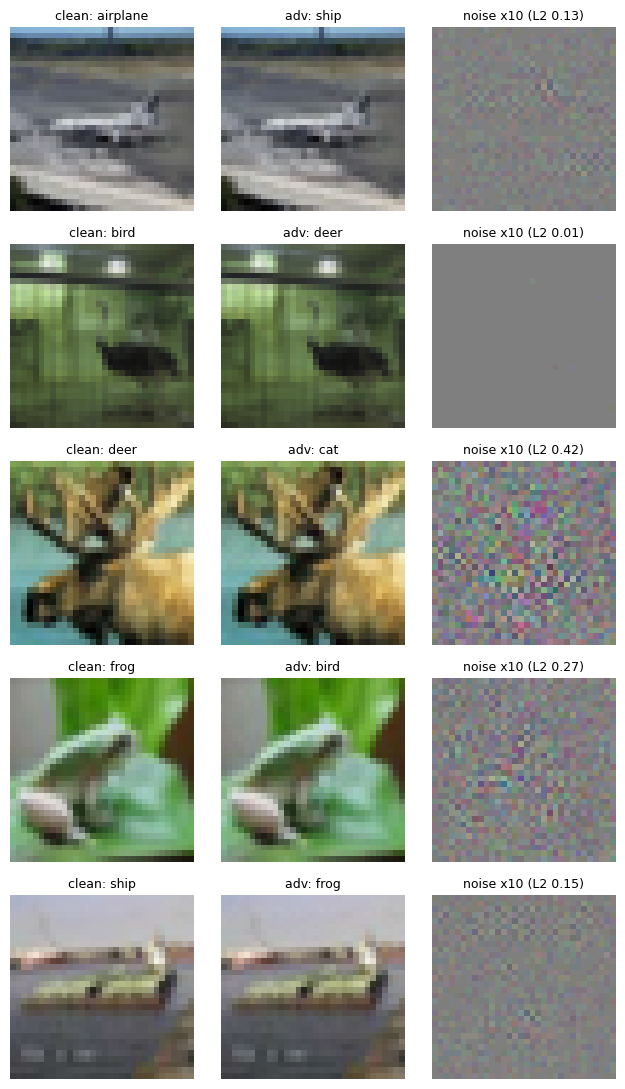

In [13]:
show = [baseline_idx[j] for j in (0, 4, 8, 12, 16)]
adv_show = hsja_adv[5000][[baseline_idx.index(i) for i in show]]
pred_show = oracle.predict(adv_show)
fig, axes = plt.subplots(len(show), 3, figsize=(6.5, 2.2 * len(show)))
for r, i in enumerate(show):
    clean, adv = X_pix[i], adv_show[r]
    noise = (0.5 + 10 * (adv - clean)).clamp(0, 1)
    l2_i = (adv - clean).norm().item()
    for c, (img, title) in enumerate([(clean, f"clean: {class_names[y_true[i]]}"),
                                      (adv, f"adv: {class_names[pred_show[r]]}"),
                                      (noise, f"noise x10 (L2 {l2_i:.2f})")]):
        axes[r, c].imshow(img.permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
        axes[r, c].set_title(title, fontsize=9)
        axes[r, c].axis("off")
plt.tight_layout()
plt.savefig("results/hsja_examples.png", dpi=120)
plt.show()

## **SurFree (Maho et al., CVPR 2021) — untargeted, L2**
Follows the reference code (github.com/t-maho/SurFree, `surfree.py`) with the settings from its `config_example.json`:
θ_max = 30°, ρ = 0.98, T = 1, 10 orthogonalized directions kept, binary searches capped at 10 steps, γ = 0.01, DCT basis with
random {−1, 0, +1} signs on the low-frequency half of the coefficients. No gradient estimate — each iteration:
1. Draw a low-frequency direction `v`, Gram-Schmidt it against the last 10 directions and the current direction `u` (clean → best).
2. Test the point at ±θ_max on the circle through the clean image and the current best point,
   `x(θ) = clean + d·cos θ·(cos θ·u + sin θ·v)`, whose distance to the clean image is d·cos θ. If neither is adversarial,
   shrink θ_max by ρ and draw a new direction; otherwise grow θ_max by 1/ρ.
3. Binary search on the angle (in α = 1 − cos θ), also checking the opposite side, to find the largest adversarial angle; move there.

One deviation: `v` is orthogonalized against the *current* direction `u` (as in the paper), not the initial one as in the reference code,
so the points stay exactly on the circle. A final line search toward the clean image (as in the reference) runs before
`finalize_8bit`; 50 queries are reserved for both.

In [14]:
_k = torch.arange(32, dtype=torch.float32)
DCT = (torch.cos(math.pi * (2 * _k[None, :] + 1) * _k[:, None] / 64) * math.sqrt(2 / 32))
DCT[0] /= math.sqrt(2)
DCT = DCT.to(device)                                                     # orthonormal 32-point DCT-II matrix
SURFREE_MASK = ((_k[:, None] + _k[None, :]) < 32).float().to(device)    # low-frequency half of the coefficients

def idct2(z):
    """Inverse orthonormal 2-D DCT over the last two dimensions."""
    return DCT.T @ z @ DCT

def surfree(x_clean, x_start, y, i, budget, max_iters=100_000, theta_max=30.0, rho=0.98, T=1, n_ortho=10,
            bs_gamma=0.01, bs_max_iter=10, margin=0.01, reserve=50, trace=None):
    d_img = x_clean.numel()
    phi = budgeted_phi(y, i, budget - reserve)
    dist = lambda z: (z - x_clean).norm().item()
    rad = math.radians
    alpha = lambda th: 1 - math.cos(rad(th))

    def line_search(z, phi):
        """Binary search between clean and adversarial z, keeping the adversarial side (reference `_binary_search(boost=True)`)."""
        boost = 0.2 * x_clean + 0.8 * z
        lo_pt, hi_pt = (x_clean, boost) if phi(boost)[0] else (boost, z)
        lo, hi, thr = 0.0, 1.0, bs_gamma / (d_img * math.sqrt(d_img))
        for _ in range(bs_max_iter):
            if hi - lo <= thr:
                break
            mid = (lo + hi) / 2
            if phi((1 - mid) * lo_pt + mid * hi_pt)[0]:
                hi = mid
            else:
                lo = mid
        return (1 - hi) * lo_pt + hi * hi_pt

    best, history = x_start, []
    try:
        best = line_search(x_start, phi)
        note(trace, i, best, x_clean)
        for _ in range(max_iters):
            d = dist(best)
            u = (best - x_clean) / d
            evo = lambda th: (x_clean + d * math.cos(rad(th)) * (math.cos(rad(th)) * u + math.sin(rad(th)) * v)).clamp(0, 1)

            # 1. draw directions until one has an adversarial point at +-theta_max
            found = 0.0
            while not found:
                v = idct2(torch.randint(-1, 2, x_clean.shape, device=device).float() * SURFREE_MASK)
                for o in history[-n_ortho:] + [u]:
                    v = v - (v * o).sum() * o
                v = v / v.norm()
                history.append(v)
                for k in range(T):
                    for sign in (1, -1):
                        if phi(evo(sign * (1 - k / T) * theta_max))[0]:
                            found = sign * (1 - k / T) * theta_max
                            break
                    if found:
                        break
                theta_max = theta_max / rho if found else theta_max * rho

            # 2. binary search on the angle, also trying the opposite side
            lower, upper = found, found + math.copysign(theta_max / T, found)
            check_opp = lower > 0
            for _ in range(bs_max_iter):
                if abs(alpha(upper) - alpha(lower)) <= bs_gamma:
                    break
                mid = (lower + upper) / 2
                adv = phi(evo(mid))[0]
                adv_opp = bool(phi(evo(-mid))[0]) if check_opp else False
                if adv:
                    lower = mid
                elif adv_opp:
                    lower, upper = -mid, -upper
                else:
                    upper = mid
                check_opp = check_opp and adv_opp and lower > 0

            cand = evo(lower)
            if dist(cand) < d:
                best = cand
                note(trace, i, best, x_clean)
    except OutOfBudget:
        pass
    try:
        best = line_search(best, budgeted_phi(y, i, budget - 38))
        note(trace, i, best, x_clean)
    except OutOfBudget:
        pass
    return finalize_8bit(x_clean, best, x_start, y, i, budget, margin, trace)

## **CGBA (Reza et al., ICCV 2023) — untargeted, L2**
Follows the `CGBA` (not `CGBA_H`) method in the reference code (github.com/machanic/hard_label_attacks, `CGBA/attack_gpu.py`)
with its CIFAR-10 L2 settings from `configures/CGBA.json`: σ = 0.003, tol = 0.002, dimension-reduction factor 3, 100·√t queries per iteration.
Each iteration:
1. **Normal estimate** at the boundary point `x_b` — `100·√t` Gaussian perturbations restricted to the lowest 10×10 DCT block of each
   channel, scaled by σ; the label-weighted sum points toward the adversarial side.
2. **Curvature-aware boundary search** — in the plane spanned by the estimated normal and the direction clean → `x_b`, walk along the
   circle through the clean image and `x_b` (angles 45°, 67.5°, 78.75°, … from `x_b`, i.e. ever closer to the clean image) until a point is
   **not** adversarial, then bisect the arc between `x_b` and that point down to tol. The arc follows the curved boundary instead of the
   straight lines used by GeoDA / HSJA.

The start is the baseline point, refined with the reference binary search (to tol). 40 queries are reserved for `finalize_8bit`.

In [15]:
def cgba_noise(n, dim_reduce=3):
    """Gaussian noise in the lowest-frequency (32 / dim_reduce)^2 DCT block of each channel (reference `find_random`)."""
    f = int(32 / dim_reduce)
    z = torch.zeros(n, 3, 32, 32, device=device)
    z[:, :, :f, :f] = torch.randn(n, 3, f, f, device=device)
    return idct2(z)

def cgba(x_clean, x_start, y, i, budget, max_iters=1000, init_evals=100, sigma=0.003, tol=0.002, dim_reduce=3,
         margin=0.01, reserve=40, trace=None):
    phi = budgeted_phi(y, i, budget - reserve)
    dist = lambda z: (z - x_clean).norm().item()
    unit = lambda z: z / (z.norm() + 1e-12)
    dot = lambda a, b: (a * b).sum().item()

    def bin_search(adv):
        cln = x_clean
        for _ in range(100):
            mid = (cln + adv) / 2
            if phi(mid)[0]:
                adv = mid
            else:
                cln = mid
            if (adv - cln).norm() < tol:
                break
        return adv

    def semicircular_search(x_b, p):
        """Bisect the arc through x_clean and x_b between x_b (adversarial) and p (not adversarial)."""
        r, b_dir = dist(x_b), unit(x_b - x_clean)
        adv_dir, clean_dir = b_dir, unit(p - x_clean)
        adv, clean = x_b, x_clean
        for _ in range(100):
            mid_dir = unit(adv_dir + clean_dir)
            x_mid = (x_clean + mid_dir * dot(b_dir, mid_dir) * r).clamp(0, 1)
            if phi(x_mid)[0]:
                adv_dir, adv = mid_dir, x_mid
            else:
                clean_dir, clean = mid_dir, x_mid
            if (adv - clean).norm() < tol:
                break
        return adv

    def go_to_boundary(eta, x_b):
        """Walk along the circle from the normal direction toward x_clean until a point is not adversarial."""
        eta, v, r = unit(eta), unit(x_b - x_clean), dist(x_b)
        theta = math.acos(max(-1.0, min(1.0, dot(eta, v))))
        for k in range(1, 101):
            a = math.pi / 2 * (1 - 2.0 ** -k)
            m = math.sin(theta) * math.cos(a) / math.sin(a) - math.cos(theta)
            zeta = unit(eta + m * v)
            p = (x_clean + zeta * r * dot(v, zeta)).clamp(0, 1)
            if not phi(p)[0]:
                break
        return semicircular_search(x_b, p)

    best = x_start
    try:
        x_b = bin_search(x_start)
        best = x_b
        note(trace, i, best, x_clean)
        for t in range(1, max_iters + 1):
            n = min(int(init_evals * math.sqrt(t)), budget - reserve - oracle.queries[i].item())
            if n < 10:
                break
            noise = cgba_noise(n, dim_reduce)
            z = 1 - 2 * phi((x_b + sigma * noise).clamp(0, 1)).float()    # +1 where still the true class
            eta = -(z.view(-1, 1, 1, 1) * noise).mean(0, keepdim=True)      # points toward the adversarial side
            x_b = go_to_boundary(eta, x_b)
            if dist(x_b) < dist(best):
                best = x_b
                note(trace, i, best, x_clean)
            if dist(x_b) < 1e-4:
                break
    except OutOfBudget:
        pass
    return finalize_8bit(x_clean, best, x_start, y, i, budget, margin, trace)

## **HSJA vs SurFree vs CGBA on 50 images**
5 images per class (`<class>_0` … `<class>_4`). All three attacks start from the same baseline points (computed once here, with their
queries counted toward every budget) and run with the same seed and budgets of 1000, 2000 and 5000 queries per image.
Results go to `results/compare50/`; the per-image L2 traces from the 5000-query runs are saved to `results/compare50/traces.json`.
The full comparison takes ~25 minutes (SurFree alone ~26 min), so saved results are reused unless `RERUN_COMPARISON = True`;
the shared start points are always recomputed (deterministic, ~14 queries per image).

In [16]:
eval_idx = [c * img_per_class + k for c in range(10) for k in range(5)]
out = "results/compare50"
oracle.reset()
start50, _ = run_baseline(eval_idx)
start_q50 = oracle.queries[eval_idx].clone()
reloaded, fooled = save_and_verify(start50, eval_idx, out_dir=f"{out}/baseline_images")
per, avg = compute_metrics(X_pix[eval_idx], reloaded)
save_results("baseline", "start points shared by all attacks", eval_idx, per, avg, start_q50, fooled, folder=out)

RERUN_COMPARISON = False
attacks = {"hsja": hsja, "surfree": surfree, "cgba": cgba}
names50 = [f"{n}_{b}" for b in budgets for n in attacks]
cached = not RERUN_COMPARISON and all(os.path.exists(f"{out}/{n}.json") for n in names50 + ["traces"])
traces50 = json.load(open(f"{out}/traces.json")) if cached else {}
for name, attack in ({} if cached else attacks).items():
    for budget in budgets:
        t0, traces = time.time(), {}
        adv = run_attack(attack, eval_idx, start50, start_q50, budget, traces=traces)
        reloaded, fooled = save_and_verify(adv, eval_idx, out_dir=f"{out}/{name}_{budget}_images")
        per, avg = compute_metrics(X_pix[eval_idx], reloaded)
        q = oracle.queries[eval_idx]
        save_results(f"{name}_{budget}", f"{name} L2 untargeted, {budget} queries/image incl. start",
                     eval_idx, per, avg, q, fooled, folder=out)
        print(f"  {name} @ {budget}: {time.time() - t0:.0f}s, max queries used by any image: {q.max().item()}")
    traces50[name] = {file_stems[i]: traces[i] for i in eval_idx}   # from the largest budget
if not cached:
    with open(f"{out}/traces.json", "w") as f:
        json.dump(traces50, f)
print(f"\n{'Saved results reused' if cached else 'Fresh results'} (RERUN_COMPARISON = {RERUN_COMPARISON})")
compare_results(out, ["baseline"] + names50)

Saved 50 images to results/compare50/baseline_images | still misclassified after reload: 50/50

Saved results reused (RERUN_COMPARISON = False)
attack             n  success      L2    Linf    SSIM    PSNR  queries
baseline          50     100%   4.643   0.212   0.765   23.76     13.5
hsja_1000         50     100%   0.727   0.051   0.984   40.79    956.1
surfree_1000      50     100%   0.833   0.061   0.978   40.20    968.1
cgba_1000         50     100%   1.083   0.083   0.967   37.85    966.8
hsja_2000         50     100%   0.464   0.035   0.992   44.93   1956.3
surfree_2000      50     100%   0.522   0.042   0.990   43.75   1968.2
cgba_2000         50     100%   0.832   0.066   0.980   39.86   1966.7
hsja_5000         50     100%   0.288   0.025   0.997   48.75   4956.5
surfree_5000      50     100%   0.356   0.035   0.996   46.94   4968.3
cgba_5000         50     100%   0.682   0.060   0.985   41.26   4966.9


### **L2 distance vs queries**
For each image, the best L2 reached after each number of queries (5000-query runs; continuous points, the last point after 8-bit rounding).
Line = median over the 50 images, band = 25th–75th percentile. Log scale.

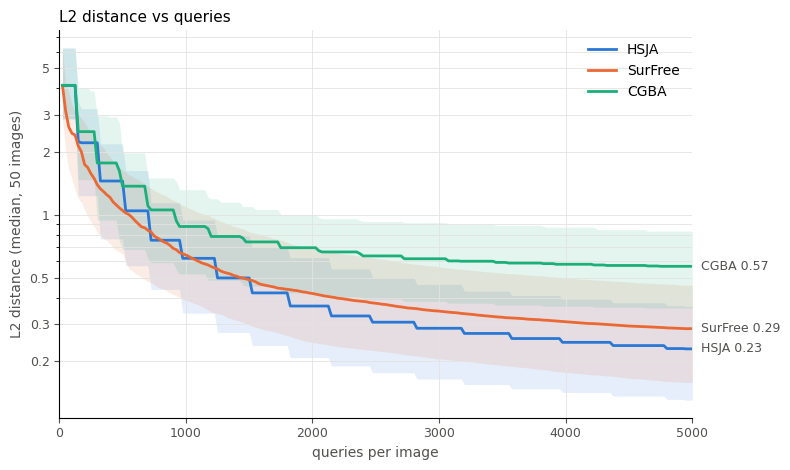

Median L2 reached within N queries
attack          250      500     1000     2000     5000
HSJA          2.202    1.447    0.619    0.366    0.229
SurFree       1.568    1.047    0.642    0.420    0.286
CGBA          2.488    1.367    0.878    0.695    0.567

Median queries to reach L2 <= t  (images that never get there count as > 5000)
attack       <= 2.0   <= 1.0   <= 0.5  <= 0.25
HSJA            325      725     1387     3975
SurFree         175      562     1450   > 5000
CGBA            300      925   > 5000   > 5000


In [17]:
import matplotlib
grid = np.arange(25, max(budgets) + 1, 25)

def curve(trace):
    """Best L2 reached within q queries for each q in grid."""
    qs = np.array([q for q, _ in trace])
    ds = np.minimum.accumulate([d for _, d in trace])
    k = np.searchsorted(qs, grid, side="right") - 1
    return np.where(k >= 0, ds[np.clip(k, 0, None)], np.nan)

curves = {n: np.array([curve(t) for t in traces50[n].values()]) for n in attacks}
colors = {"hsja": "#2a78d6", "surfree": "#eb6834", "cgba": "#1baf7a"}
labels = {"hsja": "HSJA", "surfree": "SurFree", "cgba": "CGBA"}

fig, ax = plt.subplots(figsize=(8, 4.8))
for n, c in curves.items():
    med = np.nanmedian(c, axis=0)
    lo, hi = np.nanpercentile(c, [25, 75], axis=0)
    ax.fill_between(grid, lo, hi, color=colors[n], alpha=0.12, linewidth=0)
    ax.plot(grid, med, color=colors[n], linewidth=2, label=labels[n])
    ax.annotate(f"{labels[n]} {med[-1]:.2f}", (grid[-1], med[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color="#52514e")
ax.set_yscale("log")
ax.set_yticks([0.2, 0.3, 0.5, 1, 2, 3, 5])
ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%g"))
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_xlim(0, grid[-1])
ax.set_xlabel("queries per image", color="#52514e")
ax.set_ylabel("L2 distance (median, 50 images)", color="#52514e")
ax.set_title("L2 distance vs queries", fontsize=11, loc="left")
ax.grid(True, which="both", color="#e4e3df", linewidth=0.6)
ax.tick_params(colors="#52514e", labelsize=9)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(f"{out}/l2_vs_queries.png", dpi=130, bbox_inches="tight")
plt.show()

checkpoints = [250, 500, 1000, 2000, 5000]
print("Median L2 reached within N queries")
print(f"{'attack':<10}" + "".join(f"{q:>9}" for q in checkpoints))
for n, c in curves.items():
    print(f"{labels[n]:<10}" + "".join(f"{np.nanmedian(c[:, grid == q]):>9.3f}" for q in checkpoints))

print("\nMedian queries to reach L2 <= t  (images that never get there count as > 5000)")
thresholds = [2.0, 1.0, 0.5, 0.25]
print(f"{'attack':<10}" + "".join(f"{'<= ' + str(t):>9}" for t in thresholds))
for n, c in curves.items():
    hit = c <= np.array(thresholds)[:, None, None]                        # (thresholds, images, grid)
    first = np.where(hit.any(2), grid[hit.argmax(2)], np.inf)
    med = np.median(first, axis=1)
    print(f"{labels[n]:<10}" + "".join(f"{('> 5000' if np.isinf(m) else int(m)):>9}" for m in med))

## **Improving HSJA, one change at a time**
HSJA gave the smallest noise in the comparison, so it's the attack we improve. Each change is measured on the same 50 images
at 5000 queries per image, on top of the changes kept so far, and kept only if it helps:
1. **Low-frequency search** — HSJA's random directions restricted to the lowest 16×16 or 8×8 DCT frequencies of each channel,
   so the noise is smoother. Kept if average L2 drops without losing success.
2. **Better starting points** — candidates are a uniform-noise image (if one of 10 is misclassified) plus the nearest clean image of
   **each** other predicted class; each is binary-searched (12 quantized steps) and the closest is used. Costs ~130 queries
   instead of ~14, charged to the budget. Kept if average L2 drops without losing success.
3. **Texture-aware noise** — directions multiplied by (local std / mean)^p of the clean image (3×3 window, grayscale), so more noise
   goes into textured/edgy regions. p = 0.5 and 1. Kept only if SSIM improves without losing success.
4. **Confidence margin** — the final point is pushed 0%, 2% or 5% further along clean → adversarial (1% was used so far).
   Robustness is measured with uncharged label-only checks: still fooled with TF32 on (batch 1 and batch 50) and on CPU, and still fooled
   under 10 random ±1/255 changes to 5% of the pixel values. The margin with the best jitter survival is kept, as long as success stays
   at 100%, every context passes, and average L2 grows by at most 5% over no margin.

The study takes ~12 minutes, so its saved results (`results/study50/log.json`) are reused unless `RERUN_STUDY = True`.

In [18]:
import torch.nn.functional as F

study = "results/study50"
STUDY_BUDGET = 5000
study_log, kept = [], []

def texture_map(x_clean, strength=1.0, k=3, floor=0.02):
    """(local std / mean)^strength of the grayscale clean image, broadcast to 3 channels."""
    g = x_clean.mean(1, keepdim=True)
    mu = F.avg_pool2d(g, k, 1, k // 2, count_include_pad=False)
    var = F.avg_pool2d(g * g, k, 1, k // 2, count_include_pad=False) - mu ** 2
    s = var.clamp_min(0).sqrt() + floor
    return ((s / s.mean()) ** strength).expand_as(x_clean)

def make_directions(low_freq=None, texture=None):
    """HSJA sampling directions: Gaussian, optionally only in the low_freq x low_freq lowest DCT frequencies,
    optionally scaled by the texture map."""
    def directions(n, x_clean):
        if low_freq:
            z = torch.zeros(n, *x_clean.shape[1:], device=device)
            z[:, :, :low_freq, :low_freq] = torch.randn(n, x_clean.shape[1], low_freq, low_freq, device=device)
            u = idct2(z)
        else:
            u = torch.randn(n, *x_clean.shape[1:], device=device)
        return u * texture_map(x_clean, texture) if texture else u
    return directions

def hsja_kwargs(opts):
    return {"directions": make_directions(**opts)} if any(opts.values()) else {}

def multi_start(indices, seed=0):
    """Closest binary-searched start among a noise image and the nearest clean image of each other predicted class."""
    gen = torch.Generator().manual_seed(seed)
    starts = []
    for i in indices:
        x, y = X_pix[i:i + 1], y_true[i:i + 1]
        if already_wrong[i]:
            starts.append(x)
            continue
        cands = []
        for _ in range(10):
            cand = quantize(torch.rand(1, 3, 32, 32, generator=gen).to(device))
            if oracle.is_adversarial(cand, y, idx=i):
                cands.append(cand)
                break
        for c in range(len(class_names)):
            pool = (clean_pred == c).nonzero().flatten()
            if c != y.item() and len(pool):
                cands.append(X_pix[pool[(X_pix[pool] - x).flatten(1).norm(dim=1).argmin()]].unsqueeze(0))
        found = [binary_search(x, cand, y, i) for cand in cands]
        starts.append(min(found, key=lambda s: (s - x).norm().item()))
    return torch.cat(starts)

def robustness(adv, indices, trials=10, frac=0.05):
    """Uncharged label-only checks. Returns (fooled with TF32 on at batch 1 and full batch, and on CPU;
    fooled under every one of `trials` random +-1/255 changes to `frac` of the pixel values)."""
    y = y_true[indices]
    ok = torch.ones(len(indices), dtype=torch.bool)
    torch.backends.cudnn.allow_tf32 = torch.backends.cuda.matmul.allow_tf32 = True
    try:
        with torch.no_grad():
            xn = to_normalized(adv)
            for preds in (model(xn), torch.cat([model(a[None]) for a in xn])):
                ok &= (preds != y).cpu()
    finally:
        torch.backends.cudnn.allow_tf32 = torch.backends.cuda.matmul.allow_tf32 = False
    cpu_model = torch.jit.load("./p2_data/cnn_model.pt", map_location="cpu")
    with torch.no_grad():
        ok &= cpu_model(to_normalized(adv).cpu()) != y.cpu()
    gen = torch.Generator(device=device).manual_seed(0)
    survive = torch.ones(len(indices), dtype=torch.bool)
    for _ in range(trials):
        mask = torch.rand(adv.shape, generator=gen, device=device) < frac
        step = torch.randint(-1, 2, adv.shape, generator=gen, device=device) / 255
        survive &= oracle.is_adversarial(quantize(adv + mask * step), y).cpu()
    return ok, survive

def evaluate(name, step, opts, starts, start_q, margin):
    t0 = time.time()
    adv = run_attack(hsja, eval_idx, starts, start_q, STUDY_BUDGET, margin=margin, **hsja_kwargs(opts))
    reloaded, fooled = save_and_verify(adv, eval_idx, out_dir=f"{study}/{name}_images")
    per, avg = compute_metrics(X_pix[eval_idx], reloaded)
    s = save_results(name, step, eval_idx, per, avg, oracle.queries[eval_idx], fooled, folder=study)
    ok, survive = robustness(reloaded, eval_idx)
    s.update(contexts=int(ok.sum()), jitter=survive.float().mean().item())
    study_log.append(s)
    print(f"  {name:<20} success {s['success_rate']:.0%} | L2 {s['avg_L2']:.3f} | SSIM {s['avg_SSIM']:.4f} | "
          f"all contexts {s['contexts']}/{len(eval_idx)} | jitter survival {s['jitter']:.0%} | {time.time() - t0:.0f}s")
    return s

no_worse = lambda s, ref: s["success_rate"] >= ref["success_rate"]

RERUN_STUDY = False
STUDY_LOG = f"{study}/log.json"
if not RERUN_STUDY and os.path.exists(STUDY_LOG):
    saved = json.load(open(STUDY_LOG))
    study_log, kept, FINAL = saved["log"], saved["kept"], saved["final"]
    print("Saved study results reused (RERUN_STUDY = False)")
else:
    opts, use_multi, margin = {"low_freq": None, "texture": None}, False, 0.01
    starts, start_q = start50, start_q50
    best = evaluate("0_hsja", "HSJA (1% margin)", opts, starts, start_q, margin)
    kept.append("0_hsja")

    print("\n1. Low-frequency search")
    trial = {f: evaluate(f"1_lowfreq_{f}", f"+ low-frequency directions ({f}x{f} DCT)", {**opts, "low_freq": f},
                         starts, start_q, margin) for f in (16, 8)}
    f = min(trial, key=lambda f: trial[f]["avg_L2"])
    if trial[f]["avg_L2"] < best["avg_L2"] and no_worse(trial[f], best):
        opts["low_freq"], best = f, trial[f]
        kept.append(f"1_lowfreq_{f}")
    print("  ->", f"keep {f}x{f}" if opts["low_freq"] else "drop (no L2 improvement)")

    print("\n2. Better starting points")
    oracle.reset()
    ms_starts = multi_start(eval_idx)
    ms_q = oracle.queries[eval_idx].clone()
    d_old = (start50 - X_pix[eval_idx]).flatten(1).norm(dim=1)
    d_new = (ms_starts - X_pix[eval_idx]).flatten(1).norm(dim=1)
    print(f"  start L2: baseline {d_old.mean():.3f} ({start_q50.float().mean():.0f} queries) -> "
          f"multi-start {d_new.mean():.3f} ({ms_q.float().mean():.0f} queries); closer for {(d_new < d_old).sum()}/{len(eval_idx)} images")
    s = evaluate("2_multistart", "+ best of several starting points", opts, ms_starts, ms_q, margin)
    if s["avg_L2"] < best["avg_L2"] and no_worse(s, best):
        use_multi, best, starts, start_q = True, s, ms_starts, ms_q
        kept.append("2_multistart")
    print("  ->", "keep" if use_multi else "drop (no L2 improvement)")

    print("\n3. Texture-aware noise")
    trial = {p: evaluate(f"3_texture_{p}", f"+ texture-weighted directions (p={p})", {**opts, "texture": p},
                         starts, start_q, margin) for p in (0.5, 1.0)}
    p = max(trial, key=lambda p: trial[p]["avg_SSIM"])
    if trial[p]["avg_SSIM"] > best["avg_SSIM"] and no_worse(trial[p], best):
        opts["texture"], best = p, trial[p]
        kept.append(f"3_texture_{p}")
    print("  ->", f"keep p={p}" if opts["texture"] else "drop (no SSIM improvement)")

    print("\n4. Confidence margin")
    trial = {m: evaluate(f"4_margin_{round(m * 100)}pct", f"margin {m:.0%}", opts, starts, start_q, m) for m in (0.0, 0.02, 0.05)}
    trial[0.01] = best
    ok_m = [m for m, s in trial.items() if no_worse(s, best) and s["contexts"] == len(eval_idx)
            and s["avg_L2"] <= 1.05 * trial[0.0]["avg_L2"]] or [0.01]
    margin = max(ok_m, key=lambda m: (trial[m]["jitter"], -m))
    if margin != 0.01:
        best = trial[margin]
        kept.append(f"4_margin_{round(margin * 100)}pct")
    print(f"  -> margin {margin:.0%}")

    FINAL = {"opts": opts, "multi_start": use_multi, "margin": margin}
    with open(f"{study}/final_config.json", "w") as fh:
        json.dump(FINAL, fh, indent=2)
    with open(STUDY_LOG, "w") as fh:
        json.dump({"log": study_log, "kept": kept, "final": FINAL}, fh, indent=2)

print("\nStudy summary (50 images, 5000 queries per image; * = kept)")
print(f"{'step':<22}{'success':>8}{'L2':>8}{'Linf':>8}{'SSIM':>8}{'PSNR':>8}{'queries':>9}{'contexts':>10}{'jitter':>8}")
for s in study_log:
    print(f"{('* ' if s['attack'] in kept else '  ') + s['attack']:<22}{s['success_rate']:>8.0%}{s['avg_L2']:>8.3f}"
          f"{s['avg_Linf']:>8.3f}{s['avg_SSIM']:>8.4f}{s['avg_PSNR']:>8.2f}{s['avg_queries']:>9.0f}"
          f"{s['contexts']:>7}/{len(eval_idx)}{s['jitter']:>8.0%}")
print("\nFinal configuration:", FINAL)

Saved study results reused (RERUN_STUDY = False)

Study summary (50 images, 5000 queries per image; * = kept)
step                   success      L2    Linf    SSIM    PSNR  queries  contexts  jitter
* 0_hsja                  100%   0.288   0.025  0.9969   48.75     4956     50/50     76%
  1_lowfreq_16            100%   0.467   0.046  0.9929   44.79     4956     50/50     76%
  1_lowfreq_8             100%   0.892   0.072  0.9794   39.05     4956     50/50     82%
  2_multistart            100%   0.295   0.027  0.9970   48.56     4957     50/50     80%
  3_texture_0.5           100%   0.309   0.037  0.9978   48.12     4956     50/50     78%
* 3_texture_1.0           100%   0.365   0.058  0.9979   46.64     4956     50/50     76%
  4_margin_0pct           100%   0.362   0.058  0.9979   46.74     4956     48/50     34%
  4_margin_2pct           100%   0.369   0.059  0.9979   46.55     4956     50/50     82%
* 4_margin_5pct           100%   0.379   0.061  0.9977   46.26     4956     50/5

## **Adversarial Attack**
Implement your attack in the following cell.
1. You can only call `model()` as a **black box oracle** and use the output.
2. Your method **must not** see the actual parameters or architecture.
3. Your method **must not** see the intermediate layer outputs including class probabilities.

In [19]:
# IMPLEMENT YOUR ATTACK HERE
# Final attack: HSJA (untargeted, L2, labels only through `oracle`) with the configuration chosen by the study above (FINAL),
# 5000 queries per image including the start search. Runs in chunks of 100 images; each finished chunk is saved to
# results/final/checkpoints/, and chunks that already have a checkpoint are skipped, so a crashed run resumes where it stopped.
FINAL = json.load(open("results/study50/final_config.json"))
FINAL_BUDGET = 5000
CKPT_DIR, CHUNK = "results/final/checkpoints", 100
os.makedirs(CKPT_DIR, exist_ok=True)
all_idx = list(range(len(X)))
print("Final configuration:", FINAL, "| budget", FINAL_BUDGET)

t_run, done = time.time(), 0
for c0 in range(0, len(all_idx), CHUNK):
    idx = all_idx[c0:c0 + CHUNK]
    path = f"{CKPT_DIR}/chunk_{c0:04d}.pt"
    if os.path.exists(path):
        print(f"images {c0:4d}-{idx[-1]:4d}: checkpoint found, skipped")
        continue
    t0 = time.time()
    oracle.reset()
    starts = multi_start(idx, seed=c0) if FINAL["multi_start"] else run_baseline(idx, seed=c0)[0]
    start_q = oracle.queries[idx].clone()
    adv = run_attack(hsja, idx, starts, start_q, FINAL_BUDGET, seed=c0, margin=FINAL["margin"], **hsja_kwargs(FINAL["opts"]))
    fooled = oracle.is_adversarial(adv, y_true[idx]).cpu()
    torch.save({"idx": idx, "adv": torch.round(adv * 255).to(torch.uint8).cpu(),
                "start": torch.round(starts * 255).to(torch.uint8).cpu(), "queries": oracle.queries[idx].clone()}, path)
    done += len(idx)
    left = len(all_idx) - c0 - len(idx)
    eta = (time.time() - t_run) / done * left
    l2 = (adv - X_pix[idx]).flatten(1).norm(dim=1)
    print(f"images {c0:4d}-{idx[-1]:4d}: fooled {fooled.sum().item()}/{len(idx)} | mean L2 {l2.mean():.3f} | "
          f"mean queries {oracle.queries[idx].float().mean():.0f} | {time.time() - t0:.0f}s | ETA {eta / 60:.1f} min")
print(f"Done in {(time.time() - t_run) / 60:.1f} min")

Final configuration: {'opts': {'low_freq': None, 'texture': 1.0}, 'multi_start': False, 'margin': 0.05} | budget 5000
images    0-  99: checkpoint found, skipped
images  100- 199: checkpoint found, skipped
images  200- 299: checkpoint found, skipped
images  300- 399: checkpoint found, skipped
images  400- 499: checkpoint found, skipped
images  500- 599: checkpoint found, skipped
images  600- 699: checkpoint found, skipped
images  700- 799: checkpoint found, skipped
images  800- 899: checkpoint found, skipped
images  900- 999: checkpoint found, skipped
Done in 0.0 min


## **Save Adversarial Images**
1. You must save the one adversarial image corresponding to each clean image as `.png`.
2. You must follow the naming convention. For example, the adversarial image corresponding to `cat_5.png` must be saved as `cat_5_adv.png`, so that during evaluation they can be compared.
3. Save all the adversarial images in the same folder and name it `adv_images`.
4. Make sure the images are properly denormalized using the same `mean` and `std`. This is essential since it can affect the quality of your adversarial images if not done properly.

In [20]:
# SAVE ADVERSARIAL IMAGES
# 1. Load every checkpoint and save all 1000 images to p2_data/adv_images/<name>_adv.png (save_and_verify reloads them and checks).
# 2. Any saved image that's no longer misclassified -- in FP32, or with TF32 on / on CPU (see `robustness`) -- is pushed further along
#    clean -> adversarial (x1.02, 1.05, ... 2, else its start point) until it passes in every context, and everything is re-saved
#    and re-checked. Each try costs 1 oracle query + 3 context checks, all charged to that image.
# 3. Report the final metrics, check the folder has exactly the 1000 expected files, and write per-image metrics to results.csv.
import csv

ckpts = [torch.load(f"{CKPT_DIR}/chunk_{c0:04d}.pt") for c0 in range(0, len(all_idx), CHUNK)]
assert [i for c in ckpts for i in c["idx"]] == all_idx, "missing checkpoints: re-run the attack cell"
adv_final = torch.cat([c["adv"] for c in ckpts]).float().div(255).to(device)
start_final = torch.cat([c["start"] for c in ckpts]).float().div(255).to(device)

oracle.reset()
oracle.queries[all_idx] = torch.cat([c["queries"] for c in ckpts])
adv_dir = "p2_data/adv_images"
reloaded, fooled = save_and_verify(adv_final, all_idx, out_dir=adv_dir)
ok_ctx, _ = robustness(reloaded, all_idx, trials=0)

def passes_everywhere(cand, j):
    """FP32 oracle check, then the context checks with cand in its place in the full batch (TF32 labels depend on the batch)."""
    i = all_idx[j]
    if not oracle.is_adversarial(cand, y_true[i:i + 1], idx=i)[0]:
        return False
    oracle.queries[i] += 3
    batch = reloaded.clone()
    batch[j] = cand[0]
    return robustness(batch, all_idx, trials=0)[0][j].item()

fixed = []
for rnd in range(3):
    fails = (~(fooled & ok_ctx)).nonzero().flatten().tolist()
    if not fails:
        break
    for j in fails:
        i = all_idx[j]
        x, cand, how = X_pix[i:i + 1], start_final[j:j + 1], "start point"
        for s in (1.02, 1.05, 1.1, 1.2, 1.5, 2.0, 3.0, 5.0):
            c = quantize(x + s * (adv_final[j:j + 1] - x))
            if not torch.equal(c, adv_final[j:j + 1]) and passes_everywhere(c, j):   # skip scales that round to the same image
                cand, how = c, f"x{s}"
                break
        adv_final[j] = cand[0]
        fixed.append(f"{file_stems[i]} ({how})")
    print(f"Fix round {rnd + 1}: re-saving after pushing {len(fails)} image(s) further")
    reloaded, fooled = save_and_verify(adv_final, all_idx, out_dir=adv_dir)
    ok_ctx, _ = robustness(reloaded, all_idx, trials=0)
print(f"Images fixed after saving: {len(fixed)}", fixed if fixed else "")

per, avg = compute_metrics(X_pix[all_idx], reloaded)
queries = oracle.queries[all_idx].clone()
adv_pred = oracle.predict(reloaded).cpu()
ok_ctx, survive = robustness(reloaded, all_idx)
files = sorted(os.path.basename(p) for p in glob.glob(f"{adv_dir}/*.png"))
expected = sorted(f"{file_stems[i]}_adv.png" for i in all_idx)

summary = save_results("final", f"HSJA {FINAL}, {FINAL_BUDGET} queries/image", all_idx, per, avg, queries, fooled,
                       folder="results/final")
summary.update(total_queries=int(queries.sum()), fixed_after_saving=len(fixed), all_contexts=int(ok_ctx.sum()),
               jitter_survival=survive.float().mean().item())
with open("results/final/summary.json", "w") as fh:
    json.dump(summary, fh, indent=2)

with open("results.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["image", "true_label", "adv_label", "fooled", "queries", "L2", "Linf", "SSIM", "PSNR"])
    for j, i in enumerate(all_idx):
        w.writerow([f"{file_stems[i]}_adv.png", class_names[y_true[i]], class_names[adv_pred[j]], bool(fooled[j]),
                    int(queries[j]), f"{per['L2'][j]:.6f}", f"{per['Linf'][j]:.6f}", f"{per['SSIM'][j]:.6f}", f"{per['PSNR'][j]:.4f}"])

print(f"\nFinal results on {len(all_idx)} images (from the saved PNGs)")
print(f"  success rate      {fooled.float().mean():.1%}  ({fooled.sum().item()}/{len(all_idx)})")
print(f"  average L2        {avg['L2']:.4f}")
print(f"  average L-inf     {avg['Linf']:.4f}  ({avg['Linf'] * 255:.1f}/255)")
print(f"  average SSIM      {avg['SSIM']:.4f}")
print(f"  average PSNR      {avg['PSNR']:.2f} dB")
print(f"  total queries     {int(queries.sum()):,}")
print(f"  average queries   {queries.float().mean():.1f}  (max {queries.max().item()})")
print(f"  still fooled with TF32 on / on CPU: {ok_ctx.sum().item()}/{len(all_idx)}")
print(f"  files in {adv_dir}: {len(files)} | names match the clean images exactly: {files == expected}")
print("  per-image metrics written to results.csv; summary to results/final/summary.json")

Saved 1000 images to p2_data/adv_images | still misclassified after reload: 1000/1000


Fix round 1: re-saving after pushing 2 image(s) further


Saved 1000 images to p2_data/adv_images | still misclassified after reload: 1000/1000


Images fixed after saving: 2 ['airplane_95 (x1.5)', 'bird_15 (x1.5)']



Final results on 1000 images (from the saved PNGs)
  success rate      100.0%  (1000/1000)
  average L2        0.3630
  average L-inf     0.0614  (15.6/255)
  average SSIM      0.9977
  average PSNR      45.86 dB
  total queries     4,956,199
  average queries   4956.2  (max 4995)
  still fooled with TF32 on / on CPU: 1000/1000
  files in p2_data/adv_images: 1000 | names match the clean images exactly: True
  per-image metrics written to results.csv; summary to results/final/summary.json


### **Submission:** Complete this notebook and submit along with adversarial images in adv_images folder.

## **Export data for the project website**
Writes everything the website in `site/` needs into `site/data/`. Every image is saved twice: the 32×32 original as `<name>_32.png`
and a 160×160 nearest-neighbour upscale as `<name>.png` (CIFAR images are tiny; nearest-neighbour keeps the pixels crisp).
Label checks here are for display only and aren't charged to any attack budget.
1. `model_demo.json` + `clean/` — 2 correctly classified clean images per class.
2. `attack_examples.json` + `attack/` — 8 images from the final submission (one per class): clean, adversarial, noise ×10 on grey, labels, metrics, queries.
3. `frames.json` + `frames/<name>/` — the attack re-run on 3 of those images with the final configuration, keeping a snapshot at each stage
   (start, binary search, every improvement of the boundary walk, final), thinned to at most 25 frames. Because it's a re-run,
   the final frame can differ slightly from the submitted image.
4. `results.json` — every method's summary (baseline, HSJA, SurFree, CGBA at each budget; the final 1000-image run), the improvement study,
   and how many clean images the model already gets wrong.

Anything that doesn't exist yet is written as a clearly marked placeholder (`"placeholder": true`, values `null`) so the site still loads.

In [21]:
SITE = "site/data"
UPSCALE = 160
SHOWCASE = ["airplane_7", "automobile_7", "bird_7", "cat_7", "deer_7", "frog_7", "horse_7", "ship_7"]
ANIMATE = ["cat_7", "deer_7", "ship_7"]
MAX_FRAMES = 25
for sub in ("clean", "attack", "frames"):
    os.makedirs(f"{SITE}/{sub}", exist_ok=True)

def save_png(img, path):
    """Save a (3, 32, 32) image in [0, 1] as a 160x160 nearest-neighbour upscale plus the 32x32 original; returns site-relative paths."""
    arr = torch.round(img.detach().clamp(0, 1) * 255).to(torch.uint8).permute(1, 2, 0).cpu().numpy()
    small = Image.fromarray(arr)
    base = os.path.splitext(path)[0]
    small.save(f"{base}_32.png")
    small.resize((UPSCALE, UPSCALE), Image.NEAREST).save(f"{base}.png")
    rel = lambda p: os.path.relpath(p, "site").replace(os.sep, "/")
    return rel(f"{base}.png"), rel(f"{base}_32.png")

def noise_x10(adv, clean):
    return (0.5 + 10 * (adv - clean)).clamp(0, 1)

def write_json(name, data):
    with open(f"{SITE}/{name}", "w") as fh:
        json.dump(data, fh, indent=2)
    print(f"wrote {SITE}/{name}")

# 1. Model showcase
demo = []
for c, cname in enumerate(class_names):
    picked = [i for i in range(c * img_per_class, (c + 1) * img_per_class) if not already_wrong[i]][:2]
    for i in picked:
        big, small = save_png(X_pix[i], f"{SITE}/clean/{file_stems[i]}.png")
        demo.append({"name": file_stems[i], "file": big, "file_32": small,
                     "true_label": cname, "predicted_label": class_names[clean_pred[i]]})
write_json("model_demo.json", {"n_images": len(X), "n_misclassified_clean": len(wrong_idx), "images": demo})

# 2. Attack showcase (from the submitted PNGs)
final_json = "results/final/final.json"
final_rows = {r["image"]: r for r in json.load(open(final_json))["per_image"]} if os.path.exists(final_json) else {}
examples = []
for stem in SHOWCASE:
    i = file_stems.index(stem)
    adv_path = f"p2_data/adv_images/{stem}_adv.png"
    if not os.path.exists(adv_path):
        examples.append({"name": stem, "placeholder": True, "true_label": class_names[y_true[i]]})
        continue
    clean = X_pix[i]
    adv = transforms.ToTensor()(Image.open(adv_path).convert("RGB")).to(device)
    pred_clean, pred_adv = oracle.predict(torch.stack([clean, adv])).tolist()
    per, _ = compute_metrics(clean[None], adv[None])
    files = {}
    for key, img in (("clean", clean), ("adversarial", adv), ("noise", noise_x10(adv, clean))):
        files[key], files[key + "_32"] = save_png(img, f"{SITE}/attack/{stem}_{key}.png")
    examples.append({"name": stem, "true_label": class_names[y_true[i]], "pred_clean": class_names[pred_clean],
                     "pred_adversarial": class_names[pred_adv], "fooled": pred_adv != y_true[i].item(),
                     **{k: float(v[0]) for k, v in per.items()},
                     "queries": final_rows.get(stem, {}).get("queries"), "files": files})
write_json("attack_examples.json", {"note": "Images from the final submission (p2_data/adv_images).", "examples": examples})

# 3. Animation frames: re-run start -> binary search -> HSJA with the final configuration, keeping snapshots
class Snapshots(list):
    def __init__(self):
        super().__init__()
        self.images = []

FINAL = json.load(open("results/study50/final_config.json")) if os.path.exists("results/study50/final_config.json") else \
        {"opts": {"low_freq": None, "texture": None}, "multi_start": False, "margin": 0.01}
animations = []
for stem in ANIMATE:
    i = file_stems.index(stem)
    x, y = X_pix[i:i + 1], y_true[i:i + 1]
    torch.manual_seed(0)
    oracle.reset()
    raw, source = find_start(x, y, i, torch.Generator().manual_seed(0))
    stages = [("start", raw, oracle.queries[i].item())]
    bs = binary_search(x, raw, y, i)
    stages.append(("binary search", bs, oracle.queries[i].item()))
    snaps = Snapshots()
    hsja(x, bs, y, i, 5000, margin=FINAL["margin"], trace=snaps, **hsja_kwargs(FINAL["opts"]))
    names_ = ["binary search"] + ["boundary walk"] * (len(snaps) - 2) + ["final"]
    stages += [(st, img, q) for st, img, (q, _) in zip(names_, snaps.images, snaps)]
    if len(stages) > MAX_FRAMES:   # keep the first 3 and the last frame, thin the walk evenly
        walk = stages[3:-1]
        keep = np.linspace(0, len(walk) - 1, MAX_FRAMES - 4).round().astype(int)
        stages = stages[:3] + [walk[k] for k in sorted(set(keep))] + stages[-1:]
    folder = f"{SITE}/frames/{stem}"
    os.makedirs(folder, exist_ok=True)
    frames = []
    for k, (stage, img, q) in enumerate(stages):
        img = img[0]
        big, small = save_png(img, f"{folder}/{k:03d}.png")
        nbig, nsmall = save_png(noise_x10(img, x[0]), f"{folder}/{k:03d}_noise.png")
        label = class_names[oracle.predict(img[None])[0]]
        frames.append({"stage": stage, "file": big, "file_32": small, "noise": nbig, "noise_32": nsmall,
                       "l2": (img - x[0]).norm().item(), "label": label, "queries": int(q)})
    big, small = save_png(x[0], f"{folder}/clean.png")
    animations.append({"name": stem, "true_label": class_names[y.item()], "start_source": source,
                       "clean": big, "clean_32": small, "frames": frames})
    print(f"  {stem}: {len(frames)} frames, L2 {frames[0]['l2']:.2f} -> {frames[-1]['l2']:.3f}, {frames[-1]['queries']} queries")
write_json("frames.json", {"note": "Attack re-run for illustration with the final configuration; labels are the model's answer "
                                   "for the attack's working image at each step.", "config": FINAL, "images": animations})

# 4. Results tables
def method_row(path, method, budget, images_note):
    row = {"method": method, "budget": budget, "images": images_note}
    if not os.path.exists(path):
        return {**row, "placeholder": True, "success_rate": None, "avg_L2": None, "avg_Linf": None,
                "avg_SSIM": None, "avg_PSNR": None, "avg_queries": None}
    s = json.load(open(path))["summary"]
    return {**row, **{k: s[k] for k in ("n_images", "success_rate", "avg_L2", "avg_Linf", "avg_SSIM", "avg_PSNR", "avg_queries")}}

methods = [method_row("results/compare50/baseline.json", "Baseline", None, "50 test images")]
for b in budgets:
    for key, label in (("hsja", "HSJA"), ("surfree", "SurFree"), ("cgba", "CGBA")):
        methods.append(method_row(f"results/compare50/{key}_{b}.json", label, b, "50 test images"))
methods.append(method_row("results/final/final.json", "Final (HSJA + improvements)", 5000, "all 1000 images"))
final_extra = json.load(open("results/final/summary.json")) if os.path.exists("results/final/summary.json") else {}
study_saved = json.load(open("results/study50/log.json")) if os.path.exists("results/study50/log.json") else {"log": [], "kept": []}
improvements = [{"step": s["attack"], "description": s["description"], "kept": s["attack"] in study_saved["kept"],
                 **{k: s.get(k) for k in ("success_rate", "avg_L2", "avg_Linf", "avg_SSIM", "avg_PSNR", "avg_queries", "contexts", "jitter")}}
                for s in study_saved["log"]]
write_json("results.json", {"n_images": len(X), "n_misclassified_clean": len(wrong_idx), "budgets": budgets,
                            "methods": methods, "final": {**methods[-1], "total_queries": final_extra.get("total_queries"),
                                                          "fixed_after_saving": final_extra.get("fixed_after_saving")},
                            "improvements": improvements, "final_config": FINAL})

wrote site/data/model_demo.json
wrote site/data/attack_examples.json


  cat_7: 21 frames, L2 21.37 -> 0.248, 4956 queries


  deer_7: 21 frames, L2 21.96 -> 0.142, 4956 queries


  ship_7: 21 frames, L2 23.10 -> 0.289, 4956 queries
wrote site/data/frames.json
wrote site/data/results.json
